# PROJECT TITLE: Instagram Analytics: Data Cleaning and Exploratory Analysis

## Project Objective
This project analyzes Instagram post data to explore which content types, posting patterns, and traffic sources are associated with engagement and reach.

## Step 1: Load and Inspect the Dataset
First, i load the downloaded CSV file into a pandas DataFrame. Then i inspect its size, sample rows, column data types, missing values, and duplicate rows. This initial inspection helps us decide what cleaning is needed before analysis.

Project Workflow

The project will follow these steps:

Load Dataset → Inspect Data → Clean & Pre-process → Exploratory Data Analysis (EDA) → Create Visualizations → Generate Insights → Provide Recommendations → Conclusion

In [1]:
import pandas as pd

# Load the CSV file that was downloaded earlier
file_path = r"C:\Users\LENOVO\Downloads\Instagram_Analytics.csv"
df = pd.read_csv(file_path)

# Inspect the dataset
print("Dataset shape (rows, columns):", df.shape)

display(df.head())

print("\nColumn information:")
df.info()

print("\nMissing values in each column:")
display(df.isna().sum().sort_values(ascending=False))

print("\nNumber of duplicate rows:", df.duplicated().sum())

Dataset shape (rows, columns): (29999, 23)


,post_id,account_id,account_type,follower_count,media_type,content_category,traffic_source,has_call_to_action,post_datetime,post_date,...,comments,shares,saves,reach,impressions,engagement_rate,followers_gained,caption_length,hashtags_count,performance_bucket_label
0,IG0000001,7,brand,3551,reel,Technology,Home Feed,1,2024-11-30 06:00:00,2024-11-30,...,5,7,34,4327,6230,0.0385,899,100,7,medium
1,IG0000002,20,creator,31095,image,Fitness,Hashtags,1,2025-08-15 15:00:00,2025-08-15,...,10,21,68,7451,8268,0.0663,805,122,5,viral
2,IG0000003,15,brand,8167,reel,Beauty,Reels Feed,0,2025-09-11 16:00:00,2025-09-11,...,2,1,22,1639,2616,0.0531,758,115,8,high
3,IG0000004,11,creator,9044,carousel,Music,External,0,2025-09-18 03:00:00,2025-09-18,...,0,7,0,2877,3171,0.0309,402,115,7,medium
4,IG0000005,8,creator,15986,reel,Technology,Profile,0,2025-03-21 09:00:00,2025-03-21,...,8,5,21,5350,8503,0.0221,155,112,9,low



Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29999 entries, 0 to 29998
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   post_id                   29999 non-null  object 
 1   account_id                29999 non-null  int64  
 2   account_type              29999 non-null  object 
 3   follower_count            29999 non-null  int64  
 4   media_type                29999 non-null  object 
 5   content_category          29999 non-null  object 
 6   traffic_source            29999 non-null  object 
 7   has_call_to_action        29999 non-null  int64  
 8   post_datetime             29999 non-null  object 
 9   post_date                 29999 non-null  object 
 10  post_hour                 29999 non-null  int64  
 11  day_of_week               29999 non-null  object 
 12  likes                     29999 non-null  int64  
 13  comments                  29999 non-null

post_id                     0
likes                       0
hashtags_count              0
caption_length              0
followers_gained            0
engagement_rate             0
impressions                 0
reach                       0
saves                       0
shares                      0
comments                    0
day_of_week                 0
account_id                  0
post_hour                   0
post_date                   0
post_datetime               0
has_call_to_action          0
traffic_source              0
content_category            0
media_type                  0
follower_count              0
account_type                0
performance_bucket_label    0
dtype: int64


Number of duplicate rows: 0


## Initial Inspection Findings
The dataset contains 29,999 Instagram posts and 23 columns. The first five records loaded successfully. No missing values or duplicate rows were found. The date and time columns are currently stored as text and will be converted to datetime types during preprocessing. The call-to-action field is represented by 0 and 1.

## Step 2: Data Cleaning and Preprocessing

### 2.1 Check Values and Data Types
Before changing the dataset, I will check the unique values in important categorical columns and review summary statistics for numeric columns. This can reveal inconsistent labels or unusual values. I will also confirm whether the call-to-action column uses only 0 and 1.(I will run the code for Steps 2.1 and 2.2 in one cell. First, I will check the unique values in the categorical columns and review summary statistics for the numeric columns. This helps me identify unexpected labels and understand the ranges and typical values in the data. Then, in the same cell, I will convert post_datetime and post_date from text to datetime format so Python can work with them as dates.)

### 2.2 Convert Date Columns
The `post_datetime` and `post_date` columns are currently stored as text. I will convert them to datetime types so Python can correctly interpret dates and times for later analysis.

In [2]:
# Check the distinct values in categorical columns
categorical_columns = [
    "account_type",
    "media_type",
    "content_category",
    "traffic_source",
    "day_of_week",
    "performance_bucket_label",
    "has_call_to_action"
]

for column in categorical_columns:
    print(f"\n{column}:")
    print(sorted(df[column].dropna().unique()))

# Review numeric columns for unusual values
display(df.describe().T)

# Convert date and datetime columns
df["post_datetime"] = pd.to_datetime(df["post_datetime"], errors="coerce")
df["post_date"] = pd.to_datetime(df["post_date"], errors="coerce")

# Confirm the converted data types
print(df[["post_datetime", "post_date"]].dtypes)


account_type:
['brand', 'creator']

media_type:
['carousel', 'image', 'reel']

content_category:
['Beauty', 'Comedy', 'Fashion', 'Fitness', 'Food', 'Lifestyle', 'Music', 'Photography', 'Technology', 'Travel']

traffic_source:
['Explore', 'External', 'Hashtags', 'Home Feed', 'Profile', 'Reels Feed']

day_of_week:
['Friday', 'Monday', 'Saturday', 'Sunday', 'Thursday', 'Tuesday', 'Wednesday']

performance_bucket_label:
['high', 'low', 'medium', 'viral']

has_call_to_action:
[np.int64(0), np.int64(1)]


,count,mean,std,min,25%,50%,75%,max
account_id,29999.0,10.567819,5.763952,1.0,6.000,11.0000,16.000,20.000
follower_count,29999.0,10278.305477,6691.862669,3083.0,5824.000,9044.0000,10739.000,31095.000
has_call_to_action,29999.0,0.348778,0.476592,0.0,0.000,0.0000,1.000,1.000
post_hour,29999.0,11.499417,6.900587,0.0,6.000,12.0000,17.000,23.000
likes,29999.0,287.653588,317.647682,0.0,104.000,199.0000,363.000,10632.000
comments,29999.0,8.521917,10.116505,0.0,3.000,6.0000,11.000,339.000
shares,29999.0,14.426614,16.420899,0.0,5.000,10.0000,19.000,516.000
saves,29999.0,42.517284,47.808844,0.0,15.000,29.0000,54.000,1542.000
reach,29999.0,6272.475449,4985.877059,268.0,3058.000,4913.0000,7863.000,73339.000
impressions,29999.0,8466.952498,6825.900355,327.0,4102.000,6595.0000,10620.500,105203.000


post_datetime    datetime64[ns]
post_date        datetime64[ns]
dtype: object


In [2]:
df

,post_id,account_id,account_type,follower_count,media_type,content_category,traffic_source,has_call_to_action,post_datetime,post_date,...,comments,shares,saves,reach,impressions,engagement_rate,followers_gained,caption_length,hashtags_count,performance_bucket_label
0,IG0000001,7,brand,3551,reel,Technology,Home Feed,1,2024-11-30 06:00:00,2024-11-30,...,5,7,34,4327,6230,0.0385,899,100,7,medium
1,IG0000002,20,creator,31095,image,Fitness,Hashtags,1,2025-08-15 15:00:00,2025-08-15,...,10,21,68,7451,8268,0.0663,805,122,5,viral
2,IG0000003,15,brand,8167,reel,Beauty,Reels Feed,0,2025-09-11 16:00:00,2025-09-11,...,2,1,22,1639,2616,0.0531,758,115,8,high
3,IG0000004,11,creator,9044,carousel,Music,External,0,2025-09-18 03:00:00,2025-09-18,...,0,7,0,2877,3171,0.0309,402,115,7,medium
4,IG0000005,8,creator,15986,reel,Technology,Profile,0,2025-03-21 09:00:00,2025-03-21,...,8,5,21,5350,8503,0.0221,155,112,9,low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29994,IG0029995,5,brand,10739,carousel,Travel,Reels Feed,0,2024-12-18 10:00:00,2024-12-18,...,1,2,5,1564,2493,0.0032,124,127,8,low
29995,IG0029996,3,brand,10018,image,Beauty,Hashtags,0,2025-05-05 15:00:00,2025-05-05,...,2,1,7,2042,2492,0.0209,310,114,12,low
29996,IG0029997,18,creator,7486,image,Photography,Explore,1,2025-05-26 10:00:00,2025-05-26,...,10,16,59,5887,7528,0.0558,223,115,4,high
29997,IG0029998,6,creator,10034,carousel,Technology,Explore,1,2025-08-02 19:00:00,2025-08-02,...,3,0,19,5372,6312,0.0333,978,124,4,medium


### 2.4 Check Date and Time Consistency
The dataset stores the posting date and time in several columns. I will compare these values with `post_datetime` to check whether they agree. This helps identify inconsistent records before analysis.

In [4]:
# Compare the separate date, hour, and weekday fields with post_datetime
date_mismatch = df["post_date"].dt.date != df["post_datetime"].dt.date
hour_mismatch = df["post_hour"] != df["post_datetime"].dt.hour
weekday_mismatch = df["day_of_week"] != df["post_datetime"].dt.day_name()

print("Date mismatches:", date_mismatch.sum())
print("Hour mismatches:", hour_mismatch.sum())
print("Weekday mismatches:", weekday_mismatch.sum())

Date mismatches: 0
Hour mismatches: 0
Weekday mismatches: 0


### 2.5 Check for Duplicate Post IDs
I will check whether any `post_id` values appear more than once. Each post should have a unique identifier.

In [5]:
print("Duplicate post IDs:", df["post_id"].duplicated().sum())

Duplicate post IDs: 0


### 2.6 Check Numeric Values
I will check that count values are not negative, posting hours are within 0–23, and the engagement rate is between 0 and 1. I will also check that impressions are not lower than reach and that the call-to-action field contains only 0 or 1.

In [6]:
count_columns = [
    "follower_count", "likes", "comments", "shares", "saves",
    "reach", "impressions", "followers_gained",
    "caption_length", "hashtags_count"
]

print("Negative values in count columns:")
display((df[count_columns] < 0).sum())

print("\nEngagement rates outside 0 to 1:",
      ((df["engagement_rate"] < 0) | (df["engagement_rate"] > 1)).sum())

print("Posting hours outside 0 to 23:",
      ((df["post_hour"] < 0) | (df["post_hour"] > 23)).sum())

print("Rows where impressions are below reach:",
      (df["impressions"] < df["reach"]).sum())

print("Invalid call-to-action values:",
      (~df["has_call_to_action"].isin([0, 1])).sum())

Negative values in count columns:


follower_count      0
likes               0
comments            0
shares              0
saves               0
reach               0
impressions         0
followers_gained    0
caption_length      0
hashtags_count      0
dtype: int64


Engagement rates outside 0 to 1: 0
Posting hours outside 0 to 23: 0
Rows where impressions are below reach: 0
Invalid call-to-action values: 0


### 2.7 Validate Category Values
I will compare the values in each category column with the expected labels. This checks for unexpected values, such as misspellings or inconsistent labels.

In [8]:
expected_categories = {
    "account_type": ["brand", "creator"],
    "media_type": ["carousel", "image", "reel"],
    "content_category": [
        "Beauty", "Comedy", "Fashion", "Fitness", "Food",
        "Lifestyle", "Music", "Photography", "Technology", "Travel"
    ],
    "traffic_source": [
        "Explore", "External", "Hashtags", "Home Feed",
        "Profile", "Reels Feed"
    ],
    "day_of_week": [
        "Monday", "Tuesday", "Wednesday", "Thursday",
        "Friday", "Saturday", "Sunday"
    ],
    "performance_bucket_label": ["low", "medium", "high", "viral"]
}

for column, allowed_values in expected_categories.items():
    unexpected = df.loc[~df[column].isin(allowed_values), column].unique()
    print(f"{column}: {len(unexpected)} unexpected value(s) — {unexpected}")

account_type: 0 unexpected value(s) — []
media_type: 0 unexpected value(s) — []
content_category: 0 unexpected value(s) — []
traffic_source: 0 unexpected value(s) — []
day_of_week: 0 unexpected value(s) — []
performance_bucket_label: 0 unexpected value(s) — []


### 2.8 Final Cleaning Summary(summerize the cleaning results)
The dataset passed the checks for missing values, duplicate rows and post IDs, date consistency, numeric ranges, and expected category values. The date columns were converted to datetime format. No rows or values needed correction, so I will use a copy of the checked dataset for the analysis.

In [9]:
# Create a copy of the checked dataset for analysis
df_clean = df.copy()

print("Cleaned dataset shape:", df_clean.shape)
print("Total missing values:", df_clean.isna().sum().sum())
print("Duplicate rows:", df_clean.duplicated().sum())
print("Duplicate post IDs:", df_clean["post_id"].duplicated().sum())

print("\nDate column types:")
print(df_clean[["post_datetime", "post_date"]].dtypes)

Cleaned dataset shape: (29999, 23)
Total missing values: 0
Duplicate rows: 0
Duplicate post IDs: 0

Date column types:
post_datetime    datetime64[ns]
post_date        datetime64[ns]
dtype: object


### 2.9 Create Derived Columns

After completing the cleaning checks, I will prepare additional information for analysis by creating new columns from existing data. I will calculate `total_interactions` by adding each post’s likes, comments, shares, and saves. I will also extract the posting year and month from `post_datetime`. These columns will help me compare interaction levels and explore posting patterns over time. The original columns and rows will remain unchanged.


In this step, I will create three new columns from information already in the dataset:

1. `total_interactions` will be the sum of likes, comments, shares, and saves for each post. It gives me one combined measure of these interactions.
2. `post_year` will contain the year extracted from `post_datetime`.
3. `post_month` will contain the month name extracted from `post_datetime`.

These columns will help me compare total interactions and examine how posts vary over time. I will create them in smaller steps so I can check and understand each calculation.

#### 2.9.1 Calculate Total Interactions

I will create a new column called `total_interactions`. For each post, this column will add the likes, comments, shares, and saves. It gives me one combined count of these four types of interaction, which I can compare across posts during the analysis.

In [10]:
# Calculate total interactions for each post
df_clean["total_interactions"] = (
    df_clean["likes"]
    + df_clean["comments"]
    + df_clean["shares"]
    + df_clean["saves"]
)

# Display a few rows to check the calculation
display(
    df_clean[
        ["post_id", "likes", "comments", "shares", "saves", "total_interactions"]
    ].head()
)

print("Updated dataset shape:", df_clean.shape)

,post_id,likes,comments,shares,saves,total_interactions
0,IG0000001,194,5,7,34,240
1,IG0000002,449,10,21,68,548
2,IG0000003,114,2,1,22,139
3,IG0000004,91,0,7,0,98
4,IG0000005,154,8,5,21,188


Updated dataset shape: (29999, 24)


#### 2.9.2 Extract the Posting Year

I will create a `post_year` column by extracting the year from `post_datetime`. This will help me compare posts by year while keeping the original date and time information.

In [11]:
# Extract the year from post_datetime
df_clean["post_year"] = df_clean["post_datetime"].dt.year

# Preview the new year column
display(df_clean[["post_id", "post_datetime", "post_year"]].head())

print("Updated dataset shape:", df_clean.shape)

,post_id,post_datetime,post_year
0,IG0000001,2024-11-30 06:00:00,2024
1,IG0000002,2025-08-15 15:00:00,2025
2,IG0000003,2025-09-11 16:00:00,2025
3,IG0000004,2025-09-18 03:00:00,2025
4,IG0000005,2025-03-21 09:00:00,2025


Updated dataset shape: (29999, 25)


#### 2.9.3 Extract the Posting Month

I will create a `post_month` column by extracting the month name from `post_datetime`. This will help me compare posts by month. The original `post_datetime` column will remain available if I need the exact date and time.

In [12]:
# Extract the month name from post_datetime
df_clean["post_month"] = df_clean["post_datetime"].dt.month_name()

# Preview the new month column
display(df_clean[["post_id", "post_datetime", "post_month"]].head())

print("Updated dataset shape:", df_clean.shape)

,post_id,post_datetime,post_month
0,IG0000001,2024-11-30 06:00:00,November
1,IG0000002,2025-08-15 15:00:00,August
2,IG0000003,2025-09-11 16:00:00,September
3,IG0000004,2025-09-18 03:00:00,September
4,IG0000005,2025-03-21 09:00:00,March


Updated dataset shape: (29999, 26)


### Data Preprocessing Summary

- Checked for missing values; none were found.
- Checked for duplicate rows and post IDs; none were found.
- Confirmed that the date fields agree with `post_datetime`.
- Checked numeric ranges and category values; no invalid values were found.
- Converted `post_datetime` and `post_date` to datetime format.
- Created three derived columns: `total_interactions`, `post_year`, and `post_month`.
- Kept all 29,999 posts because no records needed to be removed.
- Grouping and aggregation will be used during EDA when needed to answer the project questions.

### Dataset Dimensions- Confirming the Dataset Rows and Columns

In [11]:
df

,post_id,account_id,account_type,follower_count,media_type,content_category,traffic_source,has_call_to_action,post_datetime,post_date,...,comments,shares,saves,reach,impressions,engagement_rate,followers_gained,caption_length,hashtags_count,performance_bucket_label
0,IG0000001,7,brand,3551,reel,Technology,Home Feed,1,2024-11-30 06:00:00,2024-11-30,...,5,7,34,4327,6230,0.0385,899,100,7,medium
1,IG0000002,20,creator,31095,image,Fitness,Hashtags,1,2025-08-15 15:00:00,2025-08-15,...,10,21,68,7451,8268,0.0663,805,122,5,viral
2,IG0000003,15,brand,8167,reel,Beauty,Reels Feed,0,2025-09-11 16:00:00,2025-09-11,...,2,1,22,1639,2616,0.0531,758,115,8,high
3,IG0000004,11,creator,9044,carousel,Music,External,0,2025-09-18 03:00:00,2025-09-18,...,0,7,0,2877,3171,0.0309,402,115,7,medium
4,IG0000005,8,creator,15986,reel,Technology,Profile,0,2025-03-21 09:00:00,2025-03-21,...,8,5,21,5350,8503,0.0221,155,112,9,low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29994,IG0029995,5,brand,10739,carousel,Travel,Reels Feed,0,2024-12-18 10:00:00,2024-12-18,...,1,2,5,1564,2493,0.0032,124,127,8,low
29995,IG0029996,3,brand,10018,image,Beauty,Hashtags,0,2025-05-05 15:00:00,2025-05-05,...,2,1,7,2042,2492,0.0209,310,114,12,low
29996,IG0029997,18,creator,7486,image,Photography,Explore,1,2025-05-26 10:00:00,2025-05-26,...,10,16,59,5887,7528,0.0558,223,115,4,high
29997,IG0029998,6,creator,10034,carousel,Technology,Explore,1,2025-08-02 19:00:00,2025-08-02,...,3,0,19,5372,6312,0.0333,978,124,4,medium



### Rebuild the Working Dataset
I will recreate the analysis copy from the loaded dataset. I will make sure the date columns use datetime format, then add the three columns created during preprocessing: `total_interactions`, `post_year`, and `post_month`.

In [9]:
import pandas as pd

# Make sure the date columns use datetime format
df["post_datetime"] = pd.to_datetime(df["post_datetime"])
df["post_date"] = pd.to_datetime(df["post_date"])

# Recreate the analysis copy and its derived columns
df_clean = df.copy()

df_clean["total_interactions"] = (
    df_clean["likes"]
    + df_clean["comments"]
    + df_clean["shares"]
    + df_clean["saves"]
)
df_clean["post_year"] = df_clean["post_datetime"].dt.year
df_clean["post_month"] = df_clean["post_datetime"].dt.month_name()  

print("Working dataset shape:", df_clean.shape)

Working dataset shape: (29999, 26)


 ## Step 3: Exploratory Data Analysis (EDA)                                                                                                                    3.1 Review Key Performance Measures

I will first summarize likes, comments, shares, saves, reach, impressions, engagement rate, and followers gained. These measures describe how many people saw or interacted with the posts.

The summary table shows the number of values, average, spread, smallest value, middle value (median), and largest value for each measure. Comparing the average with the median can help me notice whether a few posts with very high values may be raising the average. A high value is not automatically an error; I will consider it in context.

The engagement rate is stored as a decimal. For example, `0.0421` is approximately `4.21%`.

In [12]:
performance_columns = [
    "likes", "comments", "shares", "saves",
    "reach", "impressions", "engagement_rate", "followers_gained"
]

display(df_clean[performance_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
likes,29999.0,287.653588,317.647682,0.0,104.000,199.0000,363.000,10632.000
comments,29999.0,8.521917,10.116505,0.0,3.000,6.0000,11.000,339.000
shares,29999.0,14.426614,16.420899,0.0,5.000,10.0000,19.000,516.000
saves,29999.0,42.517284,47.808844,0.0,15.000,29.0000,54.000,1542.000
reach,29999.0,6272.475449,4985.877059,268.0,3058.000,4913.0000,7863.000,73339.000
impressions,29999.0,8466.952498,6825.900355,327.0,4102.000,6595.0000,10620.500,105203.000
engagement_rate,29999.0,0.042107,0.024095,0.0,0.024,0.0406,0.057,0.271
followers_gained,29999.0,502.152805,290.364038,0.0,251.000,501.0000,755.000,1000.000


### 3.2  Univariate Analysis:Distribution of Total Interactions

I will use a histogram to examine how total interactions are distributed across the posts. A histogram groups values into ranges and shows how many posts fall into each range. The horizontal axis will show total interactions, and the vertical axis will show the number of posts.

This chart can show whether most posts have similar interaction counts or whether a smaller number of posts have much higher counts. It gives an overall view of the data before I compare posts by category or format.

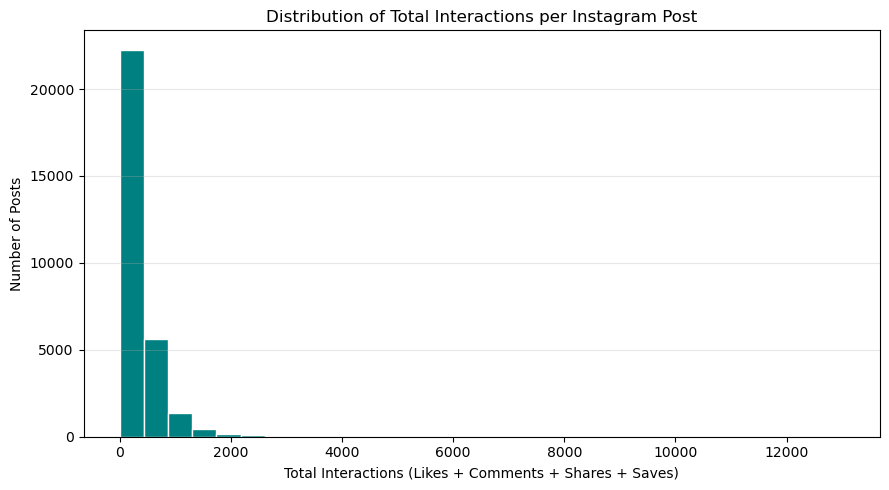

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.hist(
    df_clean["total_interactions"],
    bins=30,
    color="teal",
    edgecolor="white"
)

plt.title("Distribution of Total Interactions per Instagram Post")
plt.xlabel("Total Interactions (Likes + Comments + Shares + Saves)")
plt.ylabel("Number of Posts")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 3.3 Bivariate Analysis: Total Interactions by Media Type

I will compare the average total interactions for carousel, image, and reel posts. This examines the relationship between two features: media type and total interactions.

I will use `groupby` to collect posts with the same media type and calculate their average total interactions. This is an aggregation: it summarizes many posts as one average for each media type. I will display the averages in a bar chart. The chart can show differences in this dataset, but it cannot prove that media type caused those differences.

,media_type,total_interactions
0,carousel,351.86
1,image,355.53
2,reel,351.06


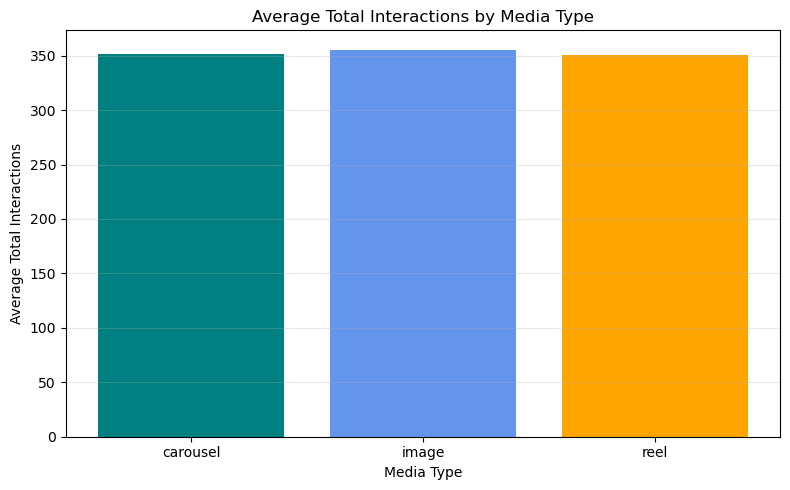

In [14]:
media_summary = (
    df_clean.groupby("media_type", as_index=False)["total_interactions"]
    .mean()
    .round(2)
)

display(media_summary)

plt.figure(figsize=(8, 5))
plt.bar(
    media_summary["media_type"],
    media_summary["total_interactions"],
    color=["teal", "cornflowerblue", "orange"]
)

plt.title("Average Total Interactions by Media Type")
plt.xlabel("Media Type")
plt.ylabel("Average Total Interactions")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 3.4 Multivariate Analysis: Account Type and Media Type

So far, I have compared total interactions with one feature at a time. In this step, I will compare account type and media type together with total interactions. This is multivariate analysis because it examines more than two features at once.

I will use a pivot table to calculate the average total interactions for each account type and media type combination. A heatmap will show those averages using colors. This may help me see whether the pattern across media types differs between brand and creator accounts.

media_type,carousel,image,reel
account_type,,,
brand,352.32,361.31,360.76
creator,351.66,353.01,346.84


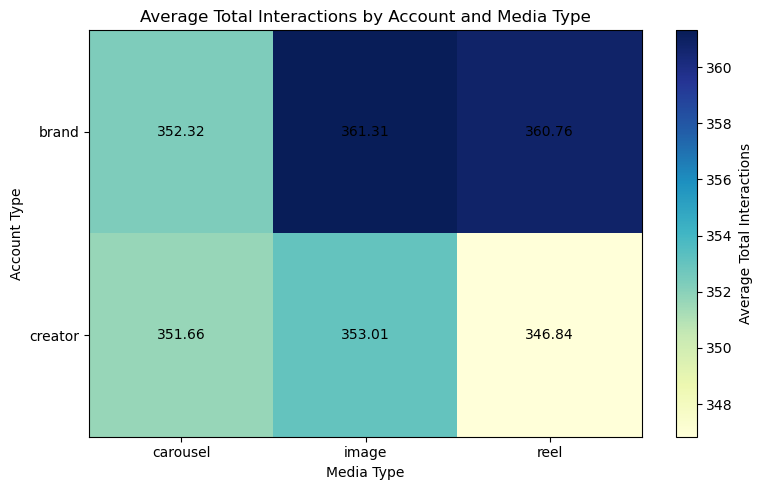

In [15]:
import matplotlib.pyplot as plt

interaction_pivot = df_clean.pivot_table(
    index="account_type",
    columns="media_type",
    values="total_interactions",
    aggfunc="mean"
).round(2)

display(interaction_pivot)

plt.figure(figsize=(8, 5))
plt.imshow(interaction_pivot, cmap="YlGnBu", aspect="auto")

plt.xticks(
    range(len(interaction_pivot.columns)),
    interaction_pivot.columns
)
plt.yticks(
    range(len(interaction_pivot.index)),
    interaction_pivot.index
)

for row in range(interaction_pivot.shape[0]):
    for column in range(interaction_pivot.shape[1]):
        plt.text(
            column, row,
            f"{interaction_pivot.iloc[row, column]:.2f}",
            ha="center", va="center"
        )

plt.title("Average Total Interactions by Account and Media Type")
plt.xlabel("Media Type")
plt.ylabel("Account Type")
plt.colorbar(label="Average Total Interactions")
plt.tight_layout()
plt.show()

#### What Aggregation Means in This Analysis

Aggregation means summarizing many individual posts into a smaller set of results. I used `groupby` to calculate the average total interactions for each media type. I also used a pivot table to compare average total interactions across account type and media type.

These summaries make it easier to compare groups. They do not remove or change the original post records; all posts remain in `df_clean`.

### 3.5 Correlation Analysis of Performance Measures

Correlation measures how two numeric values tend to vary together. A positive value means they tend to increase together; a negative value means one tends to decrease as the other increases. A value near zero means there is little linear relationship.

I will calculate correlations among likes, comments, shares, saves, reach, impressions, engagement rate, and followers gained. The table and heatmap will help me see which measures are more or less closely related. Correlation describes a relationship in this dataset; it does not prove that one measure caused another.

,likes,comments,shares,saves,reach,impressions,engagement_rate,followers_gained
likes,1.00,0.91,0.94,0.95,0.74,0.72,0.51,-0.01
comments,0.91,1.00,0.89,0.89,0.69,0.67,0.45,-0.01
shares,0.94,0.89,1.00,0.92,0.72,0.70,0.47,-0.00
saves,0.95,0.89,0.92,1.00,0.72,0.71,0.48,-0.00
reach,0.74,0.69,0.72,0.72,1.00,0.99,0.01,-0.00
impressions,0.72,0.67,0.70,0.71,0.99,1.00,-0.02,-0.01
engagement_rate,0.51,0.45,0.47,0.48,0.01,-0.02,1.00,0.00
followers_gained,-0.01,-0.01,-0.00,-0.00,-0.00,-0.01,0.00,1.00


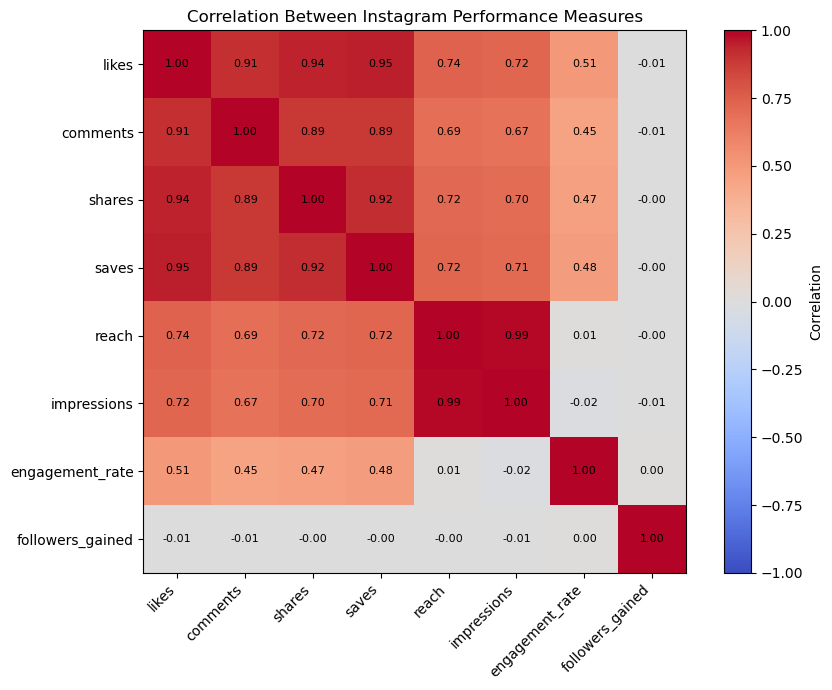

In [16]:
correlation_columns = [
    "likes", "comments", "shares", "saves",
    "reach", "impressions", "engagement_rate", "followers_gained"
]

correlation_matrix = df_clean[correlation_columns].corr()

display(correlation_matrix.round(2))

plt.figure(figsize=(9, 7))
plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.xticks(
    range(len(correlation_columns)),
    correlation_columns,
    rotation=45,
    ha="right"
)
plt.yticks(range(len(correlation_columns)), correlation_columns)

for row in range(len(correlation_columns)):
    for column in range(len(correlation_columns)):
        plt.text(
            column, row,
            f"{correlation_matrix.iloc[row, column]:.2f}",
            ha="center", va="center", fontsize=8
        )

plt.title("Correlation Between Instagram Performance Measures")
plt.colorbar(label="Correlation")
plt.tight_layout()
plt.show()


### 3.6 Bivariate Analysis: Engagement Rate by Content Category

I will compare the average engagement rate across the ten content categories. I will group the posts by category and calculate the average rate for each one. The bar chart will make it easier to compare the categories. The rate is stored as a decimal, so `0.0428` is about `4.28%`.

,content_category,mean_engagement_rate
0,Music,0.0428
1,Fitness,0.0427
2,Fashion,0.0426
3,Beauty,0.0422
4,Food,0.0421
5,Technology,0.0420
6,Comedy,0.0419
7,Travel,0.0417
8,Lifestyle,0.0416
9,Photography,0.0415


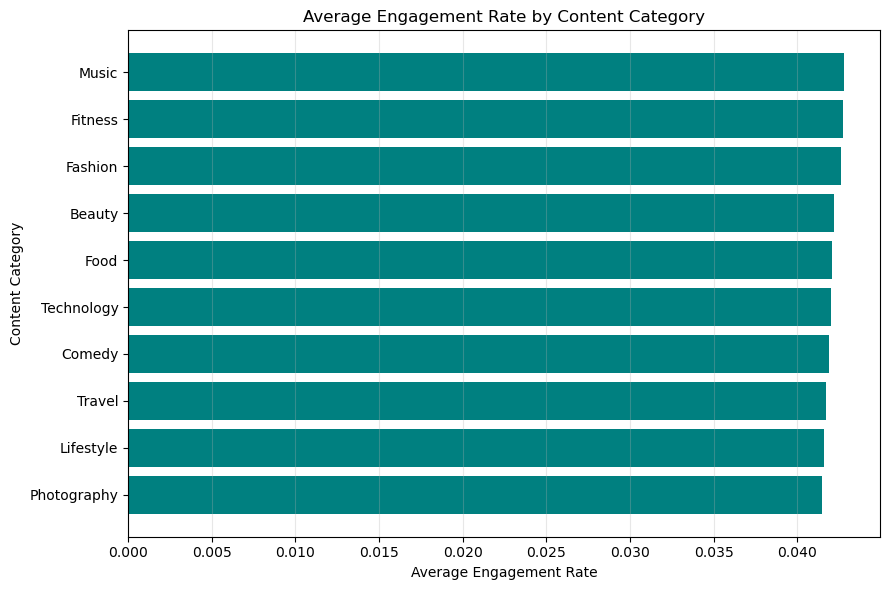

In [17]:
category_engagement = (
    df_clean.groupby("content_category")["engagement_rate"]
    .mean()
    .sort_values(ascending=False)
    .reset_index(name="mean_engagement_rate")
)

category_engagement["mean_engagement_rate"] = (
    category_engagement["mean_engagement_rate"].round(4)
)

display(category_engagement)

plt.figure(figsize=(9, 6))
plt.barh(
    category_engagement["content_category"],
    category_engagement["mean_engagement_rate"],
    color="teal"
)

plt.title("Average Engagement Rate by Content Category")
plt.xlabel("Average Engagement Rate")
plt.ylabel("Content Category")
plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### 3.7 Monthly Engagement Trend: Line Chart

I will group posts by month and calculate the average engagement rate for each month. A line chart is useful for showing how a value changes over time. The points show the monthly averages, and the connecting line makes the trend easier to follow.

I will use the full date and time column to keep the months in chronological order. This analysis summarizes the posts by month; it does not remove any posts. A change in the line shows a pattern in this dataset, but does not explain its cause.

,post_datetime,mean_engagement_rate
0,2024-11-01,0.0416
1,2024-12-01,0.0428
2,2025-01-01,0.0420
3,2025-02-01,0.0413
4,2025-03-01,0.0427
5,2025-04-01,0.0420
6,2025-05-01,0.0422
7,2025-06-01,0.0421
8,2025-07-01,0.0424
9,2025-08-01,0.0420


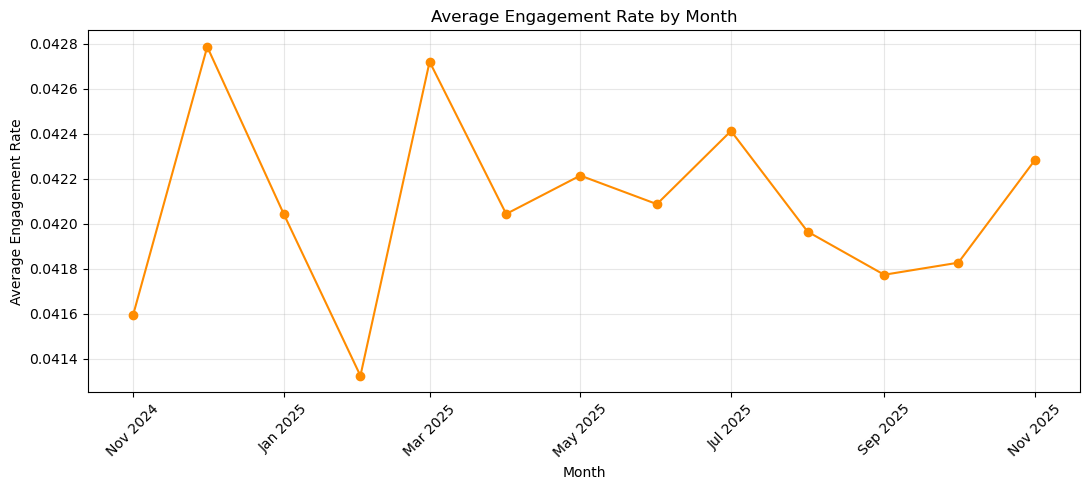

In [18]:
import matplotlib.dates as mdates

monthly_engagement = (
    df_clean.set_index("post_datetime")["engagement_rate"]
    .resample("MS")
    .mean()
)

monthly_engagement_table = (
    monthly_engagement
    .rename("mean_engagement_rate")
    .reset_index()
)

display(monthly_engagement_table.round(4))

plt.figure(figsize=(11, 5))
plt.plot(
    monthly_engagement_table["post_datetime"],
    monthly_engagement_table["mean_engagement_rate"],
    marker="o",
    color="darkorange"
)

plt.title("Average Engagement Rate by Month")
plt.xlabel("Month")
plt.ylabel("Average Engagement Rate")
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Reload the Analysis Dataset

If the Jupyter kernel restarts, its variables are cleared. I will reload the CSV, convert the date columns, and recreate the analysis copy with the three derived columns before continuing.

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

# Reload the original CSV
file_path = r"C:\Users\LENOVO\Downloads\Instagram_Analytics.csv"
df = pd.read_csv(file_path)

# Convert the date columns
df["post_datetime"] = pd.to_datetime(df["post_datetime"])
df["post_date"] = pd.to_datetime(df["post_date"])

# Recreate the analysis dataset and derived columns
df_clean = df.copy()
df_clean["total_interactions"] = (
    df_clean["likes"]
    + df_clean["comments"]
    + df_clean["shares"]
    + df_clean["saves"]
)
df_clean["post_year"] = df_clean["post_datetime"].dt.year
df_clean["post_month"] = df_clean["post_datetime"].dt.month_name()

print("Analysis dataset shape:", df_clean.shape)

Analysis dataset shape: (29999, 26)


### 3.8 Filtering by Account Type: Scatter Plot of Reach and Impressions

I will compare reach and impressions for brand and creator posts using a scatter plot. Each point represents one post. The horizontal axis shows reach, and the vertical axis shows impressions. The colors distinguish brand posts from creator posts.

I will create separate filtered subsets for the two account types. This does not delete posts from `df_clean`; it lets me compare the groups in the chart.

Brand posts: 9055
Creator posts: 20944


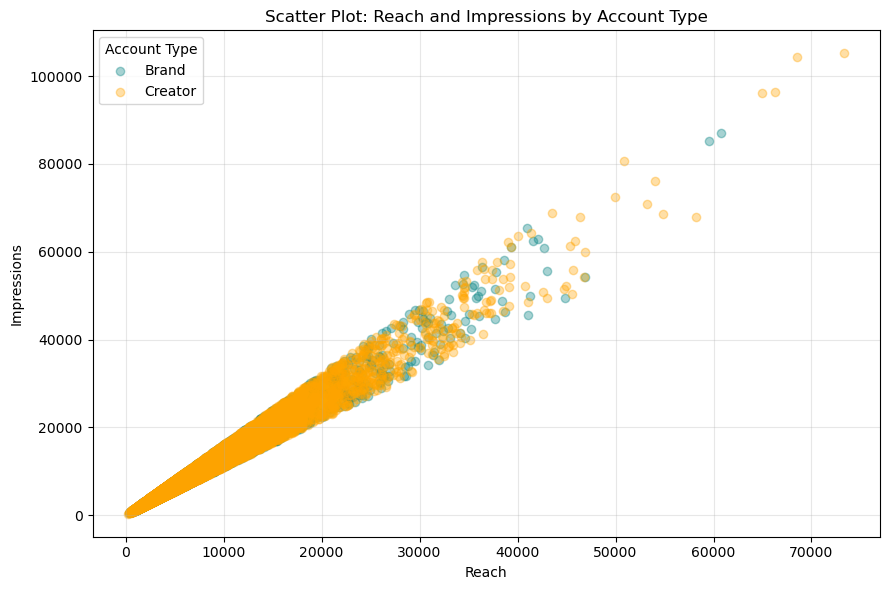

In [20]:
import matplotlib.pyplot as plt

# Create subsets for the comparison
brand_posts = df_clean[df_clean["account_type"] == "brand"]
creator_posts = df_clean[df_clean["account_type"] == "creator"]

print("Brand posts:", len(brand_posts))
print("Creator posts:", len(creator_posts))

# Make the scatter plot
plt.figure(figsize=(9, 6))

plt.scatter(
    brand_posts["reach"],
    brand_posts["impressions"],
    alpha=0.35,
    label="Brand",
    color="teal"
)

plt.scatter(
    creator_posts["reach"],
    creator_posts["impressions"],
    alpha=0.35,
    label="Creator",
    color="orange"
)

plt.title("Scatter Plot: Reach and Impressions by Account Type")
plt.xlabel("Reach")
plt.ylabel("Impressions")
plt.legend(title="Account Type")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 3.9 Box Plot: Engagement Rate by Media Type

I will compare the distribution of engagement rates for carousel, image, and reel posts. A box plot shows the middle value (median), the spread of the middle half of the posts, and points that are unusually high or low. This helps me compare more than just the average engagement rate for each media type.

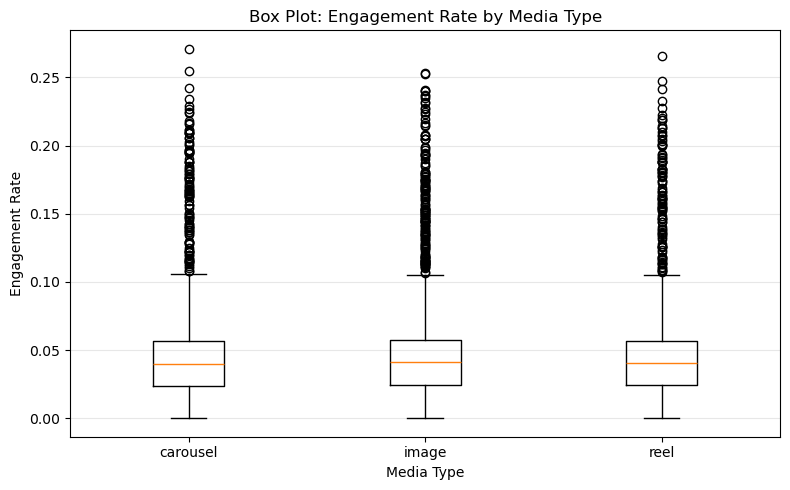

In [21]:
media_types = ["carousel", "image", "reel"]

engagement_data = [
    df_clean.loc[
        df_clean["media_type"] == media_type,
        "engagement_rate"
    ]
    for media_type in media_types
]

plt.figure(figsize=(8, 5))
plt.boxplot(engagement_data)

plt.xticks(range(1, len(media_types) + 1), media_types)
plt.title("Box Plot: Engagement Rate by Media Type")
plt.xlabel("Media Type")
plt.ylabel("Engagement Rate")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 3.10 Violin Plot: Total Interactions by Media Type

I will compare total interactions across carousel, image, and reel posts using a violin plot. The width of each violin shows where values are more concentrated: wider areas contain more posts. This lets me compare the shape and spread of interactions across media types.

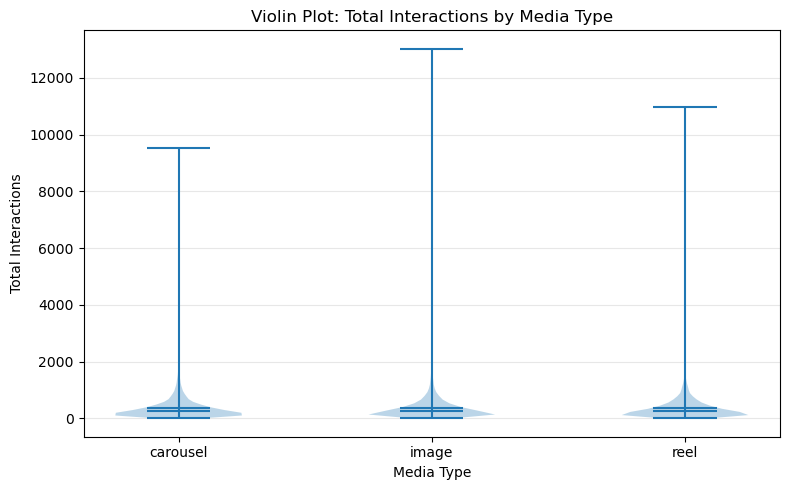

In [22]:
import matplotlib.pyplot as plt

media_types = ["carousel", "image", "reel"]

interaction_data = [
    df_clean.loc[
        df_clean["media_type"] == media_type,
        "total_interactions"
    ]
    for media_type in media_types
]

plt.figure(figsize=(8, 5))
plt.violinplot(
    interaction_data,
    showmeans=True,
    showmedians=True
)

plt.xticks(range(1, len(media_types) + 1), media_types)
plt.title("Violin Plot: Total Interactions by Media Type")
plt.xlabel("Media Type")
plt.ylabel("Total Interactions")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 3.11 Pie Chart: Posts by Account Type

I will use a pie chart to show how the posts are divided between brand and creator accounts. Each slice represents one account type, and its size shows that type’s share of all posts. This helps me understand the composition of the dataset.

account_type
creator    20944
brand       9055
Name: count, dtype: int64


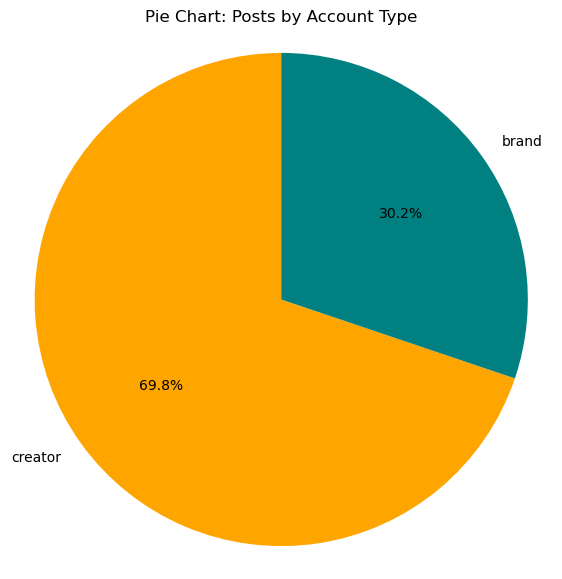

In [23]:
account_counts = df_clean["account_type"].value_counts()

print(account_counts)

plt.figure(figsize=(7, 7))
plt.pie(
    account_counts.values,
    labels=account_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["orange", "teal"]
)

plt.title("Pie Chart: Posts by Account Type")
plt.axis("equal")
plt.show()

### 3.12 Interactive Plotly Scatter Plot: Engagement Rate and Followers Gained

I will use an interactive scatter plot to compare the engagement rate and followers gained for each post. Each point represents a post, and its color shows the media type. I can hover over a point to see more details, and use the chart controls to zoom or pan. This chart helps me explore how these measures relate in the dataset; it does not prove that one caused the other.

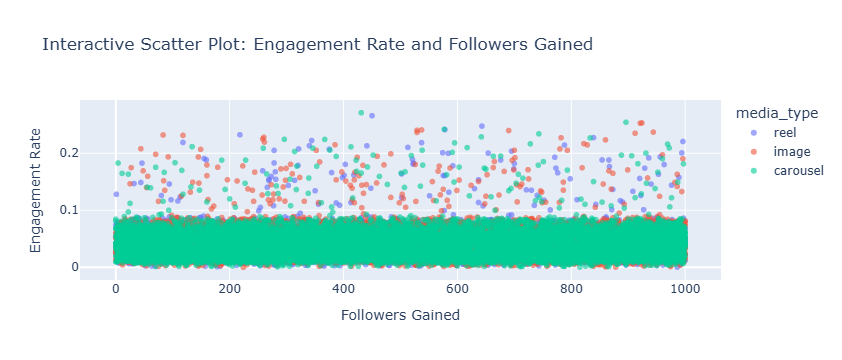

In [24]:
import plotly.express as px

fig = px.scatter(
    df_clean,
    x="followers_gained",
    y="engagement_rate",
    color="media_type",
    hover_data=["post_id", "account_type", "content_category"],
    opacity=0.6,
    title="Interactive Scatter Plot: Engagement Rate and Followers Gained"
)

fig.update_layout(
    xaxis_title="Followers Gained",
    yaxis_title="Engagement Rate"
)

fig.show()

### 3.13 Stacked Bar Chart: Performance Bucket by Call to Action

I will compare the performance-bucket percentages for posts with a call to action and posts without one. The chart uses `has_call_to_action`, where 1 means yes and 0 means no. I will convert those codes to readable labels and use a cross-tabulation to calculate the percentage in each performance bucket.

Each bar represents one call-to-action group, and its colored sections show the percentages labeled low, medium, high, and viral. This describes the groups in the dataset; it does not prove that adding a call to action caused a particular result.

performance_bucket_label,low,medium,high,viral
has_call_to_action,,,,
Has call to action,25.7,25.1,24.5,24.8
No call to action,24.6,24.9,25.3,25.1


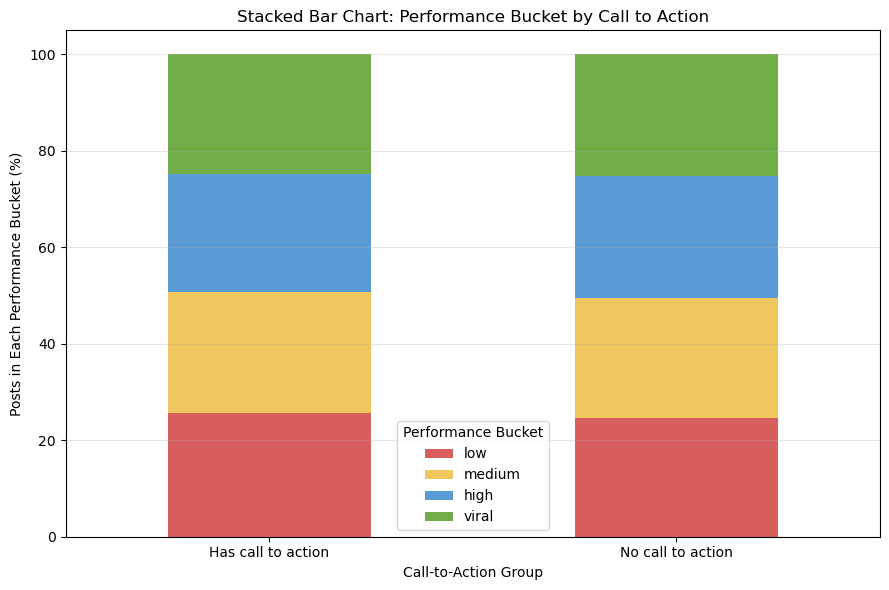

In [25]:
cta_labels = df_clean["has_call_to_action"].map({
    0: "No call to action",
    1: "Has call to action"
})

cta_performance = pd.crosstab(
    cta_labels,
    df_clean["performance_bucket_label"],
    normalize="index"
) * 100

cta_performance = cta_performance.reindex(
    columns=["low", "medium", "high", "viral"]
)

display(cta_performance.round(1))

ax = cta_performance.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 6),
    color=["#d95f5f", "#f0c75e", "#5b9bd5", "#70ad47"]
)

ax.set_title("Stacked Bar Chart: Performance Bucket by Call to Action")
ax.set_xlabel("Call-to-Action Group")
ax.set_ylabel("Posts in Each Performance Bucket (%)")
ax.legend(title="Performance Bucket")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 3.14 Area Chart: Number of Posts by Month

I will count the posts published in each month and display the counts in an area chart. This chart shows how the volume of posts changes over time. Comparing it with the monthly engagement-rate chart can help me see whether months with more posts also had different average engagement rates.

,post_datetime,post_count
0,2024-11-01,1004
1,2024-12-01,2532
2,2025-01-01,2587
3,2025-02-01,2322
4,2025-03-01,2499
5,2025-04-01,2509
6,2025-05-01,2579
7,2025-06-01,2494
8,2025-07-01,2535
9,2025-08-01,2509


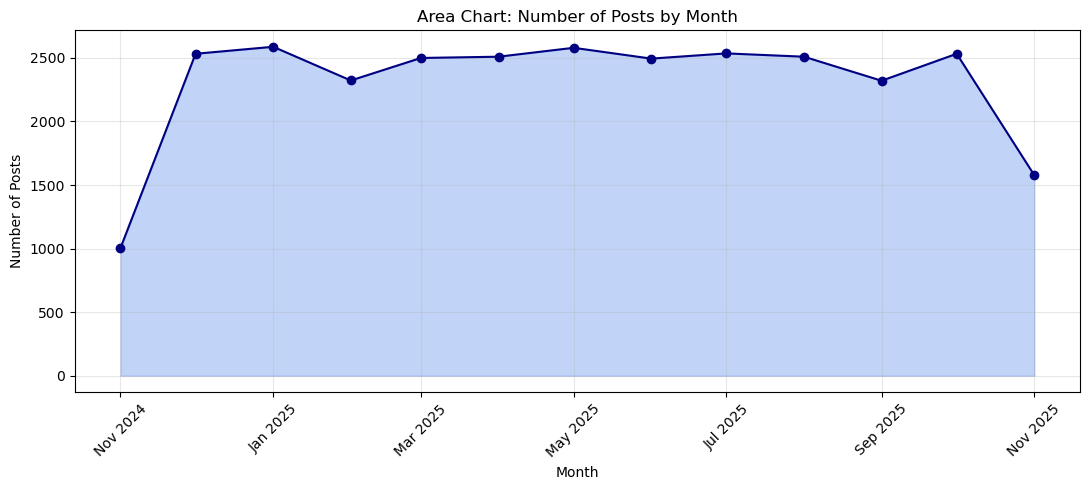

In [26]:
import matplotlib.dates as mdates

monthly_posts = (
    df_clean.set_index("post_datetime")
    .resample("MS")
    .size()
    .rename("post_count")
    .reset_index()
)

display(monthly_posts)

plt.figure(figsize=(11, 5))
plt.fill_between(
    monthly_posts["post_datetime"],
    monthly_posts["post_count"],
    color="cornflowerblue",
    alpha=0.4
)
plt.plot(
    monthly_posts["post_datetime"],
    monthly_posts["post_count"],
    marker="o",
    color="navy"
)

plt.title("Area Chart: Number of Posts by Month")
plt.xlabel("Month")
plt.ylabel("Number of Posts")
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 3.15 Hexbin Plot- its a (Matplotlib) chart type : Caption Length and Total Interactions

This plot helps show where many data points are concentrated.I will compare caption length with total interactions using a hexbin plot. Each hexagon represents posts with similar caption lengths and interaction counts. The color shows how many posts fall in that area. This helps me see where posts are concentrated and whether the two measures appear related.

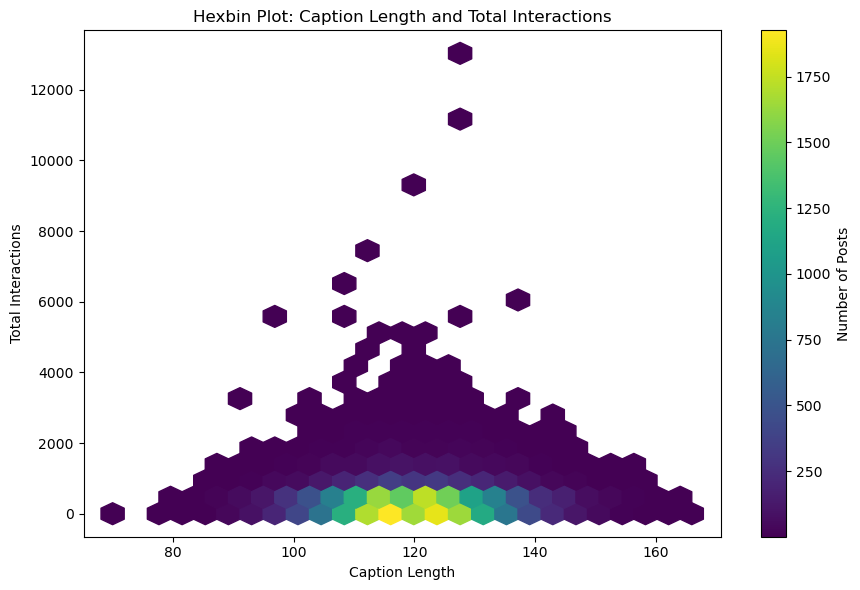

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

hex_plot = plt.hexbin(
    df_clean["caption_length"],
    df_clean["total_interactions"],
    gridsize=25,
    mincnt=1,
    cmap="viridis"
)

plt.title("Hexbin Plot: Caption Length and Total Interactions")
plt.xlabel("Caption Length")
plt.ylabel("Total Interactions")
plt.colorbar(hex_plot, label="Number of Posts")
plt.tight_layout()
plt.show()

### 3.16 Stacked Area Chart (Matplotlib): Monthly Posts by Media Type

I will group the posts by month and media type, then show the monthly counts in a stacked area chart. Each colored area represents one media type. This chart helps me see how the number and mix of carousel, image, and reel posts changed over time.


media_type,carousel,image,reel
month_start,,,
2024-11-01,363,385,256
2024-12-01,939,993,600
2025-01-01,929,1032,626
2025-02-01,816,936,570
2025-03-01,868,996,635
2025-04-01,864,1003,642
2025-05-01,916,1040,623
2025-06-01,891,994,609
2025-07-01,885,1019,631


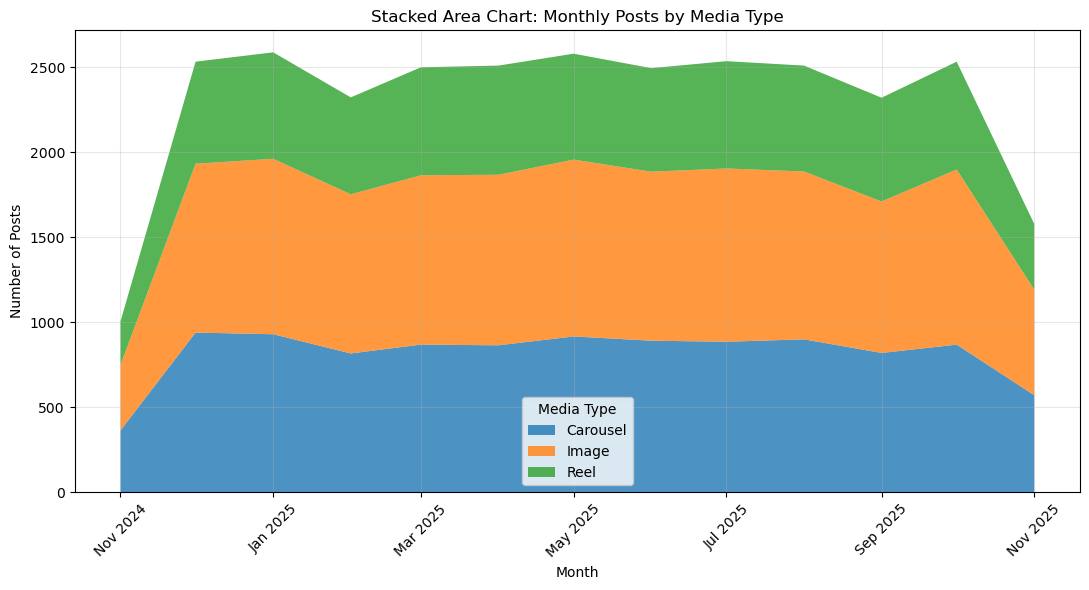

In [29]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

monthly_media_counts = (
    df_clean.assign(
        month_start=df_clean["post_datetime"].dt.to_period("M").dt.to_timestamp()
    )
    .groupby(["month_start", "media_type"])
    .size()
    .unstack(fill_value=0)
)

# Keep the media types in a consistent order
monthly_media_counts = monthly_media_counts[
    ["carousel", "image", "reel"]
]

display(monthly_media_counts)

plt.figure(figsize=(11, 6))
plt.stackplot(
    monthly_media_counts.index,
    monthly_media_counts["carousel"],
    monthly_media_counts["image"],
    monthly_media_counts["reel"],
    labels=["Carousel", "Image", "Reel"],
    alpha=0.8
)

plt.title("Stacked Area Chart: Monthly Posts by Media Type")
plt.xlabel("Month")
plt.ylabel("Number of Posts")
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.xticks(rotation=45)
plt.legend(title="Media Type")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Step 4: Visualizations

I created charts to help show the patterns found during the EDA. The charts include distributions, comparisons, relationships, and changes over time. They use clear titles, labels, and colors to make the results easier to understand.

### 4.1 Subplots: Distributions of Engagement Measures

I will use four subplots in one figure to show the distributions of likes, comments, shares, and saves. Each panel shows one measure. Putting them together makes it easier to compare these engagement measures in one view.

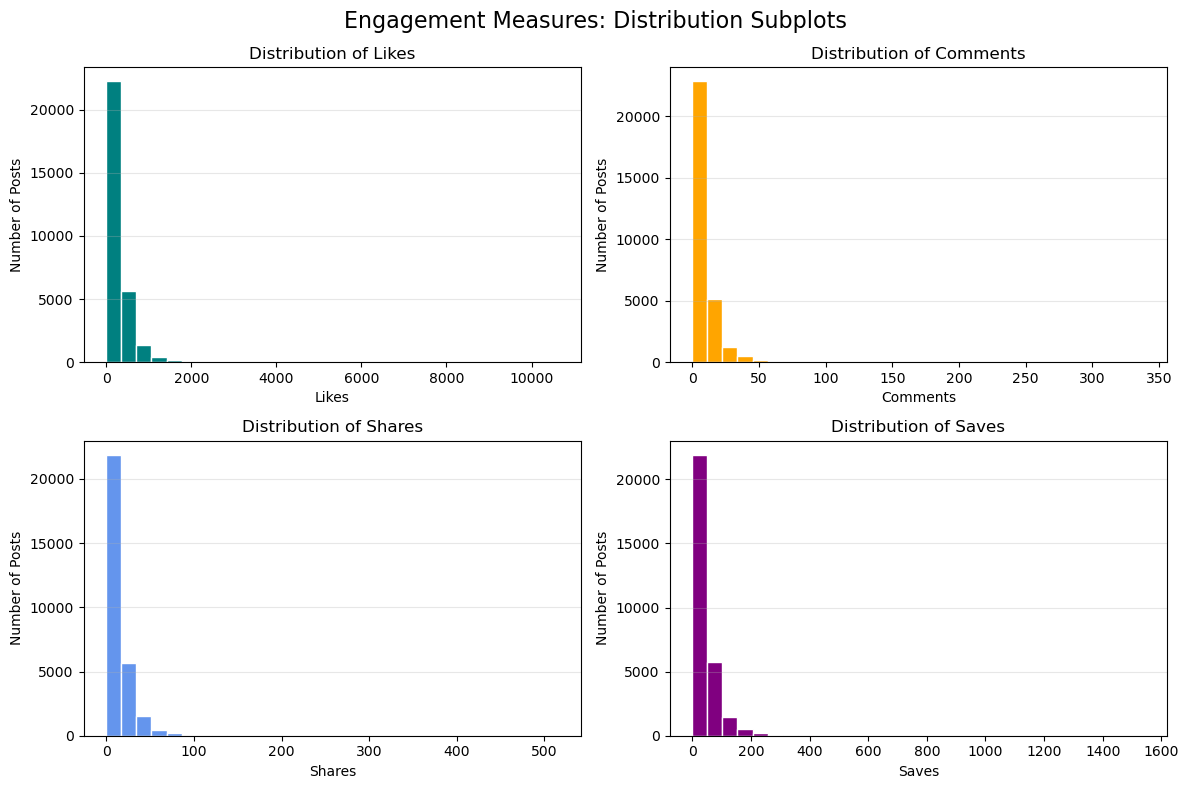

In [30]:
engagement_measures = ["likes", "comments", "shares", "saves"]
colors = ["teal", "orange", "cornflowerblue", "purple"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, column, color in zip(axes.flat, engagement_measures, colors):
    ax.hist(df_clean[column], bins=30, color=color, edgecolor="white")
    ax.set_title(f"Distribution of {column.title()}")
    ax.set_xlabel(column.replace("_", " ").title())
    ax.set_ylabel("Number of Posts")
    ax.grid(axis="y", alpha=0.3)

fig.suptitle("Engagement Measures: Distribution Subplots", fontsize=16)
fig.tight_layout()
plt.show()

## Step 5: Key Insights

1. **Average interactions are similar across media types.** Image posts averaged 355.53 total interactions, carousel posts 351.86, and reels 351.06. The differences are small in this dataset.

2. **Engagement rates are similar across content categories.** Music had the highest average rate at about 4.28%, and Photography had the lowest at about 4.15%. The gap is small.

3. **Most posts in this dataset are from creator accounts.** Creators account for 20,944 posts (about 69.8%), while brands account for 9,055 (about 30.2%). Overall results may therefore reflect creator posts more strongly.

4. **The account type and media type comparison also shows small differences.** Brand image posts had the highest average total interactions at 361.31. Creator reels had the lowest at 346.84.

5. **Posts with a call to action did not have a higher average in these results.** Posts without one averaged 353.68 total interactions, compared with 352.08 for posts with one. Their average engagement rates were also close: about 4.22% and 4.19%.  
6. **The correlation heatmap shows strong relationships among several measures.** Reach and impressions have a correlation of 0.99. Likes, comments, shares, and saves also have strong positive correlations with one another. Engagement rate has moderate positive correlations with these interaction counts, while followers gained has correlations close to zero. These are relationships in the dataset; they do not show that one measure caused another.
                                                                                                                                                                                                                                        These findings describe patterns in this dataset. They do not prove that a particular post feature caused higher or lower performance.

Recommendation and Next Steps
Posts with a call to action had slightly lower average interactions and engagement rates in this dataset, but the difference was small. This does not prove that calls to action reduce engagement. As a next step, test different call-to-action styles on similar posts and compare their results.

conclusion
This analysis helped identify important patterns in Instagram post performance, including engagement, reach, content types, account types, and call-to-action usage. The results show that differences between media types, content categories, and call-to-action usage were generally small in this dataset, while reach and impressions and the different engagement measures showed strong relationships.
However, these results describe patterns and relationships in the dataset and do not prove that one factor directly caused another. Overall, the analysis provides a better understanding of the factors associated with Instagram post performance and can help guide further analysis and content decisions.

Recommendation

Posts with a call to action had slightly lower average interactions and engagement rates than posts without one. Since the difference was small, it is recommended to test different call-to-action styles across similar posts rather than assuming that a call to action always improves engagement. Other factors such as content type, media type, posting time, and audience should also be considered when evaluating post performance.

Next Steps

A useful next step would be to compare different call-to-action styles across similar posts and analyze their engagement rates. Further analysis could also explore how posting time, traffic source, content category, and media type influence reach and engagement.

Conclusion

This analysis helped identify important patterns in Instagram post performance, including engagement, reach, content types, account types, and call-to-action usage. The results show that differences between media types, content categories, and call-to-action usage were generally small in this dataset, while reach and impressions and the different engagement measures showed strong relationships.

Overall, these findings describe patterns and relationships in the dataset and do not prove that one factor directly caused another. The analysis provides a better understanding of Instagram post performance and can help guide future content analysis and decision-making.